# Threshold Comparison

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels
sns.set()

# sinr dataset lpt-r 5 percentile

In [2]:
thresh_sinr_lpt_r_5 = pd.read_csv(
    "../thresholds/thresh_sinr_ds_coords_lpt_r_5.csv"
)

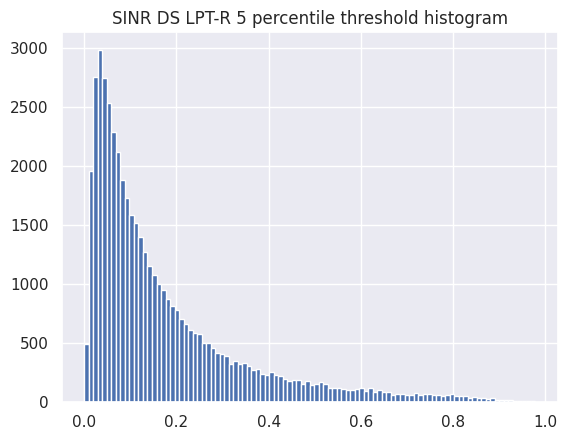

In [3]:
ax = thresh_sinr_lpt_r_5.threshold_value.hist(
    bins=100
)

ax.set_title("SINR DS LPT-R 5 percentile threshold histogram")

plt.show()

# 2.21 dataset lpt-r 5 percentile

In [35]:
train_data_2_21 = pd.read_parquet(
    "/data-ssd/alex/datasets/vision-export-20250216070017-aka-2.21/train_data.parquet",
)

In [36]:
train_counts_2_21 = train_data_2_21.taxon_id.value_counts()

In [53]:
thresh_inat_2_21_lpt_r_5 = pd.read_csv(
    "../thresholds/thresh_inat_2_21_lpt_r_5.csv"
)

In [54]:
thresh_inat_2_21_lpt_r_5.set_index("taxon_id", inplace=True)
thresh_inat_2_21_lpt_r_5["train_counts"] = train_counts

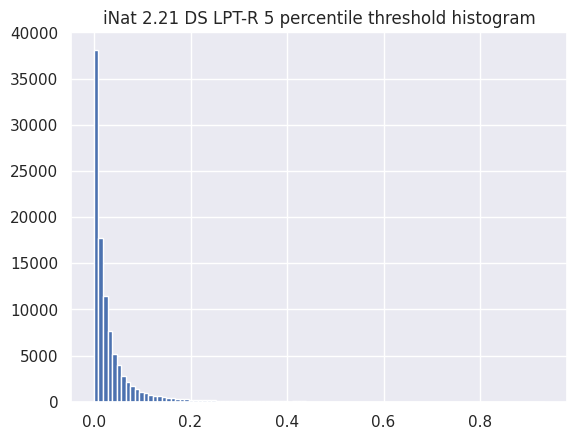

In [55]:
ax = thresh_inat_2_21_lpt_r_5.threshold_value.hist(
    bins=100
)

ax.set_title("iNat 2.21 DS LPT-R 5 percentile threshold histogram")

plt.show()

# compare 2.21 vs sinr

In [56]:
thresh_merged = pd.merge(
    thresh_inat_2_21_lpt_r_5,
    thresh_sinr_lpt_r_5,
    how="inner",
    left_on="taxon_id", 
    right_on="taxon_id",
    suffixes=["_2_21", "_sinr"],
)

thresh_merged["log_train_count"] = np.log10(thresh_merged["train_counts_2_21"] + 1)

<Axes: xlabel='threshold_value_sinr', ylabel='threshold_value_2_21'>

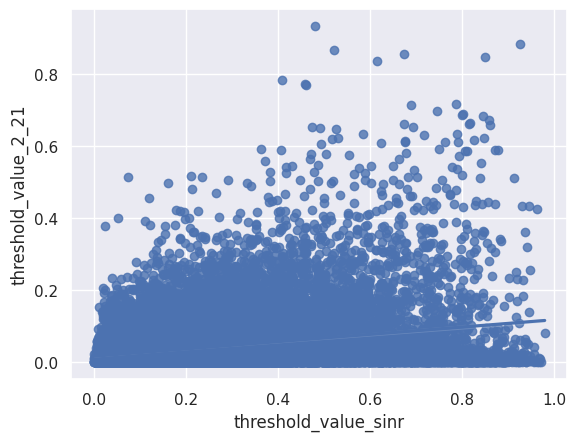

In [59]:
sns.regplot(
    thresh_merged,
    y="threshold_value_2_21",
    x="threshold_value_sinr",
)

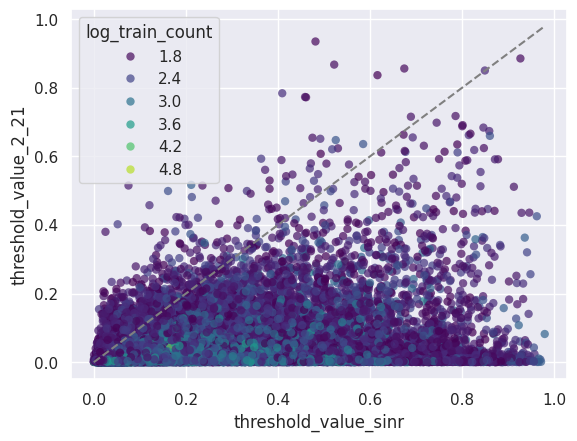

In [62]:
sns.scatterplot(
    data=thresh_merged,
    x="threshold_value_sinr",
    y="threshold_value_2_21",
    hue="log_train_count",
    palette="viridis",
    edgecolor=None,
    alpha=0.7,
    linewidth=0
)

# Plot y = x diagonal for comparison
max_val = max(thresh_merged["threshold_value_2_21"].max(), thresh_merged["threshold_value_sinr"].max())
plt.plot([0, max_val], [0, max_val], linestyle="--", color="gray", label="y = x")


# let's compare training data with thresholds

In [63]:
sinr_train_data = pd.read_parquet(
    "/home/alex/sinr/data/train/geo_prior_train.parquet"
)

In [64]:
train_counts = sinr_train_data.taxon_id.value_counts()

In [66]:
# thresh_sinr_lpt_r_5.set_index("taxon_id", inplace=True)
thresh_sinr_lpt_r_5["train_counts"] = train_counts

In [67]:
thresh_sinr_lpt_r_5.head()

,threshold_type,threshold_value,train_counts
taxon_id,,,
7,lpt_r_at_5_pct,0.054123,5115
14,lpt_r_at_5_pct,0.445995,432
19,lpt_r_at_5_pct,0.260006,313
25,lpt_r_at_5_pct,0.665095,60
26,lpt_r_at_5_pct,0.275478,173


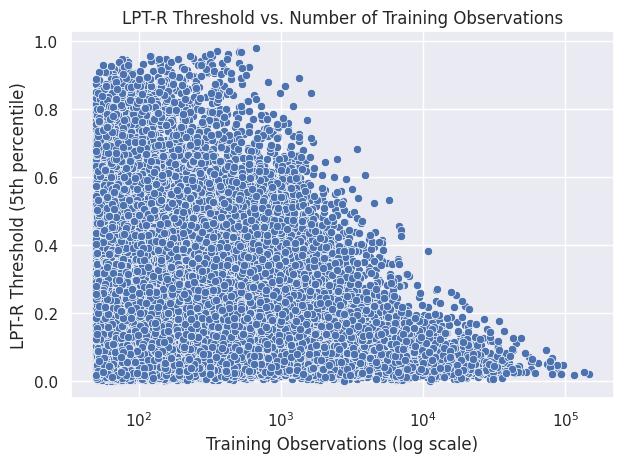

In [68]:
sns.scatterplot(
    data=thresh_sinr_lpt_r_5,
    x="train_counts",
    y="threshold_value"
)

plt.xscale("log")
plt.title("LPT-R Threshold vs. Number of Training Observations")
plt.xlabel("Training Observations (log scale)")
plt.ylabel("LPT-R Threshold (5th percentile)")
plt.tight_layout()

plt.show()

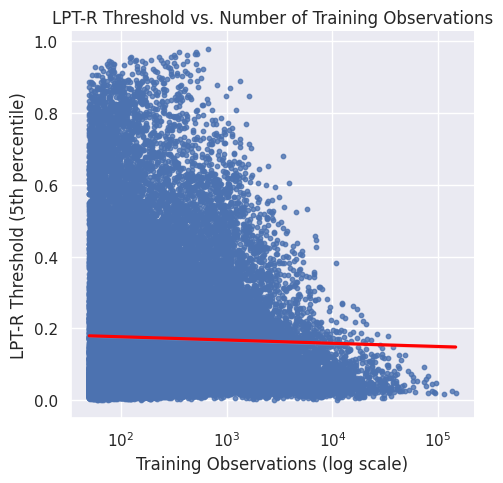

In [69]:
sns.lmplot(
    data=thresh_sinr_lpt_r_5,
    x="train_counts",
    y="threshold_value",
    scatter_kws={"s": 10},
    line_kws={"color": "red"},
    logx=True
)

plt.xscale("log")
plt.title("LPT-R Thraeshold vs. Number of Training Observations")
plt.xlabel("Training Observations (log scale)")
plt.ylabel("LPT-R Threshold (5th percentile)")
plt.tight_layout()

plt.show()

Text(0.5, 1.0, 'Option 1: Fit a local quantile trend line')

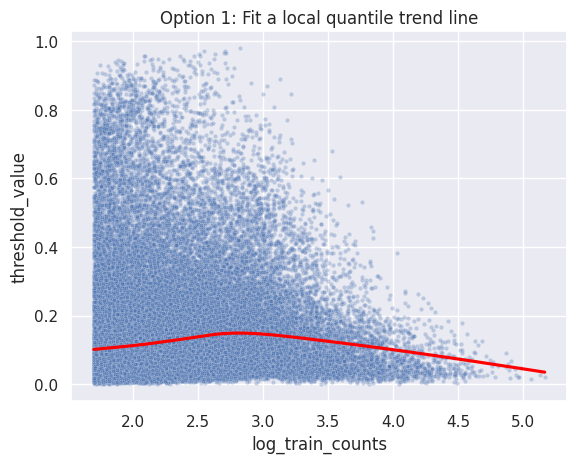

In [70]:
thresh_sinr_lpt_r_5["log_train_counts"] = np.log10(
    thresh_sinr_lpt_r_5["train_counts"]
)

sns.regplot(
    data=thresh_sinr_lpt_r_5,
    x="log_train_counts",
    y="threshold_value",
    scatter=False,
    lowess=True,
    color="red"
)
sns.scatterplot(
    data=thresh_sinr_lpt_r_5,
    x="log_train_counts",
    y="threshold_value",
    s=10,
    alpha=0.3
)

plt.title("Option 1: Fit a local quantile trend line")

In [71]:
bins = pd.cut(
    thresh_sinr_lpt_r_5["train_counts"], 
    bins=np.logspace(1.5, 5, 30)
)
bins.iloc[:5]

taxon_id
7     (4703.42, 6210.169]
14      (385.662, 509.21]
19      (292.09, 385.662]
25        (55.129, 72.79]
26     (167.547, 221.222]
Name: train_counts, dtype: category
Categories (29, interval[float64, right]): [(31.623, 41.753] < (41.753, 55.129] < (55.129, 72.79] < (72.79, 96.108] ... (32903.446, 43444.123] < (43444.123, 57361.525] < (57361.525, 75737.392] < (75737.392, 100000.0]]

In [72]:
grouped = thresh_sinr_lpt_r_5.groupby(bins)["threshold_value"]
quantiles = grouped.quantile(0.95)
quantiles

/tmp/ipykernel_112697/1433016328.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = thresh_sinr_lpt_r_5.groupby(bins)["threshold_value"]


train_counts
(31.623, 41.753]               NaN
(41.753, 55.129]          0.612282
(55.129, 72.79]           0.631595
(72.79, 96.108]           0.628312
(96.108, 126.896]         0.595222
(126.896, 167.547]        0.586003
(167.547, 221.222]        0.537916
(221.222, 292.09]         0.542079
(292.09, 385.662]         0.530365
(385.662, 509.21]         0.524460
(509.21, 672.336]         0.516624
(672.336, 887.72]         0.538578
(887.72, 1172.102]        0.535100
(1172.102, 1547.587]      0.519222
(1547.587, 2043.36]       0.435391
(2043.36, 2697.954]       0.396893
(2697.954, 3562.248]      0.363171
(3562.248, 4703.42]       0.315034
(4703.42, 6210.169]       0.283743
(6210.169, 8199.608]      0.218519
(8199.608, 10826.367]     0.184504
(10826.367, 14294.613]    0.174583
(14294.613, 18873.918]    0.184572
(18873.918, 24920.212]    0.164543
(24920.212, 32903.446]    0.136294
(32903.446, 43444.123]    0.131694
(43444.123, 57361.525]    0.120191
(57361.525, 75737.392]    0.082922
(75737.

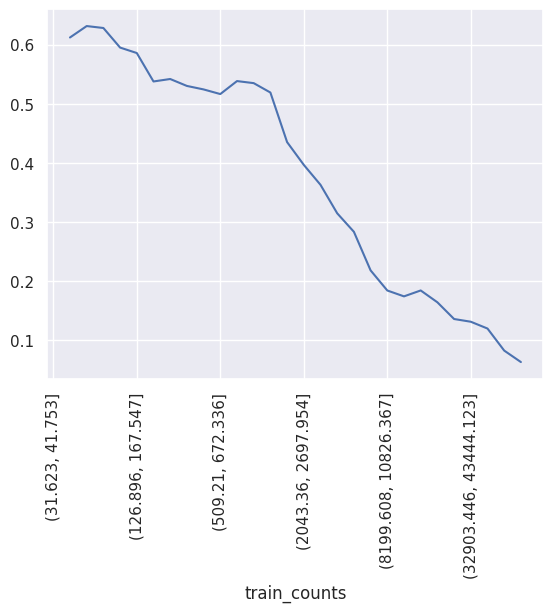

In [73]:
quantiles.plot()
plt.tick_params("x", rotation=90)
# plt.xscale("log")


/tmp/ipykernel_112697/2517036580.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = thresh_sinr_lpt_r_5.groupby(bins)["threshold_value"]


Text(0.5, 1.0, 'Option 2: 95th Percentile LPT-R Threshold vs Training Count')

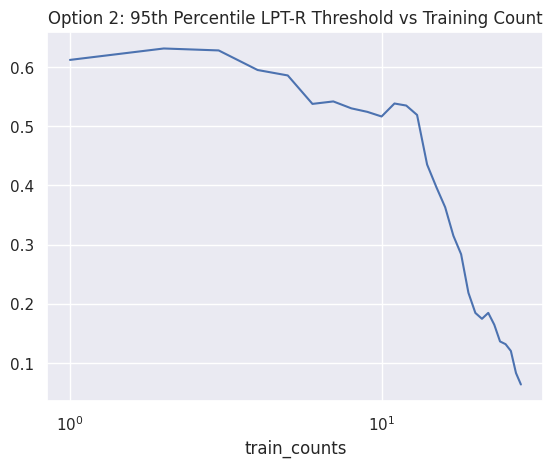

In [74]:
bins = pd.cut(thresh_sinr_lpt_r_5["train_counts"], bins=np.logspace(1.5, 5, 30))
grouped = thresh_sinr_lpt_r_5.groupby(bins)["threshold_value"]
quantiles = grouped.quantile(0.95)

quantiles.plot()
plt.xscale("log")
plt.title("Option 2: 95th Percentile LPT-R Threshold vs Training Count")

/tmp/ipykernel_112697/4072752889.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_sizes = df.groupby("binned_counts").size()
/tmp/ipykernel_112697/4072752889.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = df.groupby("binned_counts").size()


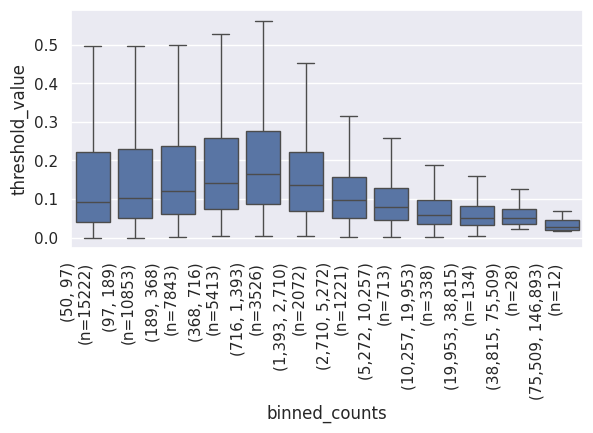

In [75]:
df = thresh_sinr_lpt_r_5.copy()
df["log_train_counts"] = np.log10(df["train_counts"])
df["binned_counts"] = pd.cut(df["log_train_counts"], bins=12)

sns.boxplot(
    data=df,
    x="binned_counts",
    y="threshold_value",
    showfliers=False  # optionally hide extreme outliers for clarity
)
# plt.tick_params("x", rotation=90)

group_sizes = df.groupby("binned_counts").size()

# Convert log10 bin edges back to raw counts
bin_edges_log = df["binned_counts"].cat.categories
bin_edges_raw = [(round(10**b.left), round(10**b.right)) for b in bin_edges_log]

# Get sample sizes per bin
bin_counts = df.groupby("binned_counts").size()

# Create readable labels: "(100, 150) (n=52)"
bin_labels = [
    f"({left:,}, {right:,})\n(n={count})"
    for (left, right), count in zip(bin_edges_raw, bin_counts)
]

plt.xticks(
    ticks=np.arange(len(bin_labels)),
    labels=bin_labels,
    rotation=90,
    ha="right"
)

plt.tight_layout(pad=2.0)

plt.show()

/tmp/ipykernel_112697/2564321287.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = df.groupby("binned_counts").size()


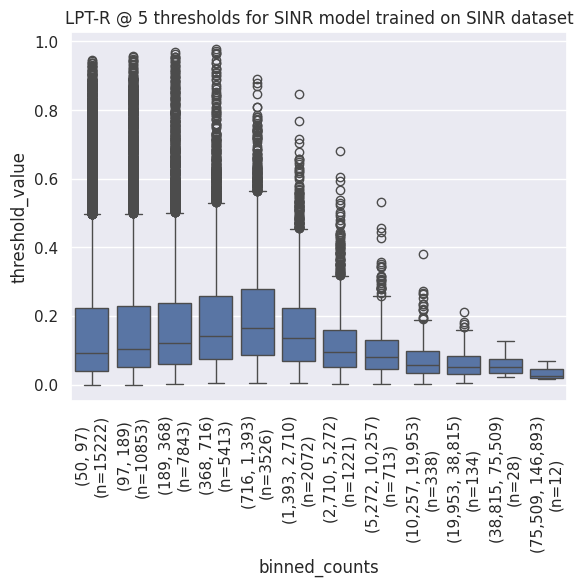

In [76]:
ax = sns.boxplot(data=df, x="binned_counts", y="threshold_value", showfliers=True)

# Build labels
bin_edges_log = df["binned_counts"].cat.categories
bin_edges_raw = [(round(10**b.left), round(10**b.right)) for b in bin_edges_log]
bin_counts = df.groupby("binned_counts").size()

labels = [
    f"({left:,}, {right:,})\n(n={count})"
    for (left, right), count in zip(bin_edges_raw, bin_counts)
]

# Apply labels using correct tick positions
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90, ha="center")

plt.title("LPT-R @ 5 thresholds for SINR model trained on SINR dataset")

plt.show()

# ok let's look at training data in 2.21 vs computed thresholds

In [ ]:
sns.scatterplsns.scatterplsns.scatterpl

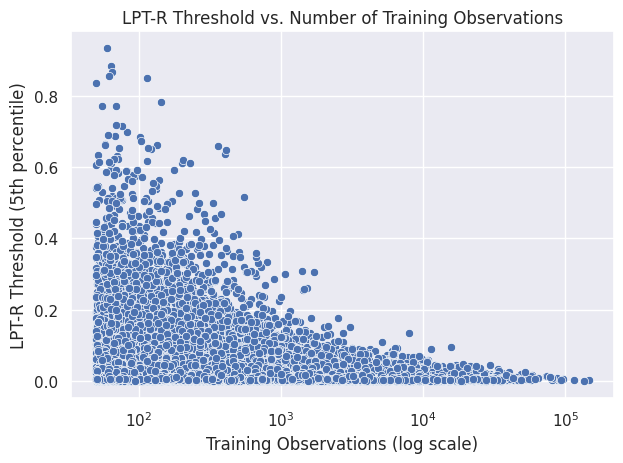

In [77]:
sns.scatterplot(
    data=thresh_inat_2_21_lpt_r_5,
    x="train_counts",
    y="threshold_value"
)

plt.xscale("log")
plt.title("LPT-R Threshold vs. Number of Training Observations")
plt.xlabel("Training Observations (log scale)")
plt.ylabel("LPT-R Threshold (5th percentile)")
plt.tight_layout()

plt.show()

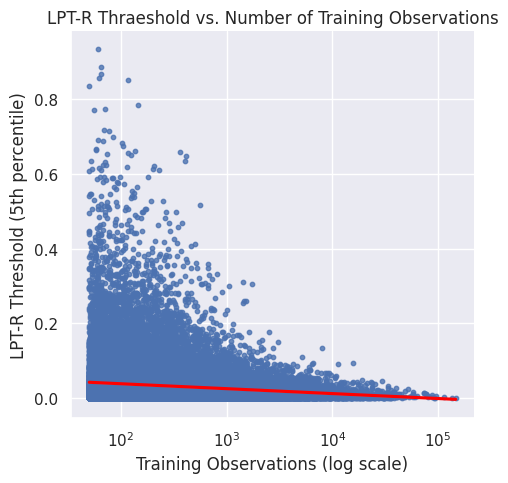

In [79]:
sns.lmplot(
    data=thresh_inat_2_21_lpt_r_5,
    x="train_counts",
    y="threshold_value",
    scatter_kws={"s": 10},
    line_kws={"color": "red"},
    logx=True
)

plt.xscale("log")
plt.title("LPT-R Thraeshold vs. Number of Training Observations")
plt.xlabel("Training Observations (log scale)")
plt.ylabel("LPT-R Threshold (5th percentile)")
plt.tight_layout()

plt.show()

Text(0.5, 1.0, 'Option 1: Fit a local quantile trend line')

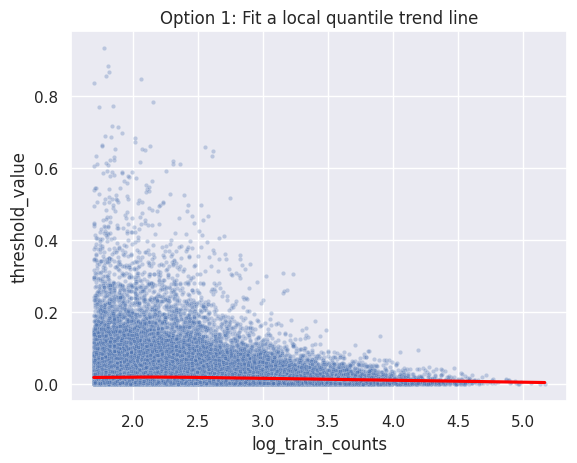

In [81]:
thresh_inat_2_21_lpt_r_5["log_train_counts"] = np.log10(
    thresh_inat_2_21_lpt_r_5["train_counts"]
)

sns.regplot(
    data=thresh_inat_2_21_lpt_r_5,
    x="log_train_counts",
    y="threshold_value",
    scatter=False,
    lowess=True,
    color="red"
)
sns.scatterplot(
    data=thresh_inat_2_21_lpt_r_5,
    x="log_train_counts",
    y="threshold_value",
    s=10,
    alpha=0.3
)

plt.title("Option 1: Fit a local quantile trend line")

/tmp/ipykernel_112697/4190663540.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = thresh_inat_2_21_lpt_r_5.groupby(bins)["threshold_value"]


Text(0.5, 1.0, 'Option 2: 95th Percentile LPT-R Threshold vs Training Count')

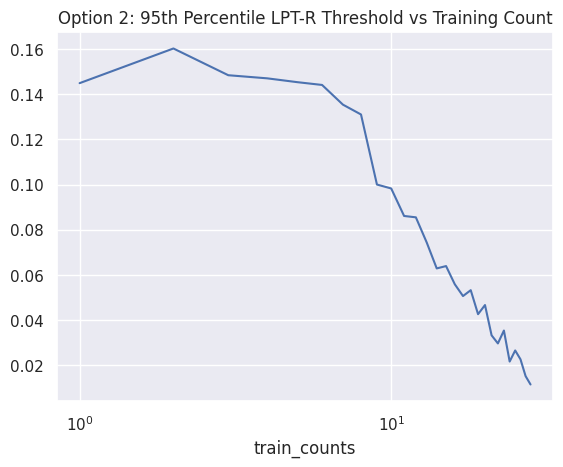

In [82]:
bins = pd.cut(thresh_inat_2_21_lpt_r_5["train_counts"], bins=np.logspace(1.5, 5, 30))
grouped = thresh_inat_2_21_lpt_r_5.groupby(bins)["threshold_value"]
quantiles = grouped.quantile(0.95)

quantiles.plot()
plt.xscale("log")
plt.title("Option 2: 95th Percentile LPT-R Threshold vs Training Count")

In [89]:
sns.set_theme(rc={'figure.figsize':(10,14)})


/tmp/ipykernel_112697/3850170849.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_sizes = df.groupby("binned_counts").size()
/tmp/ipykernel_112697/3850170849.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = df.groupby("binned_counts").size()


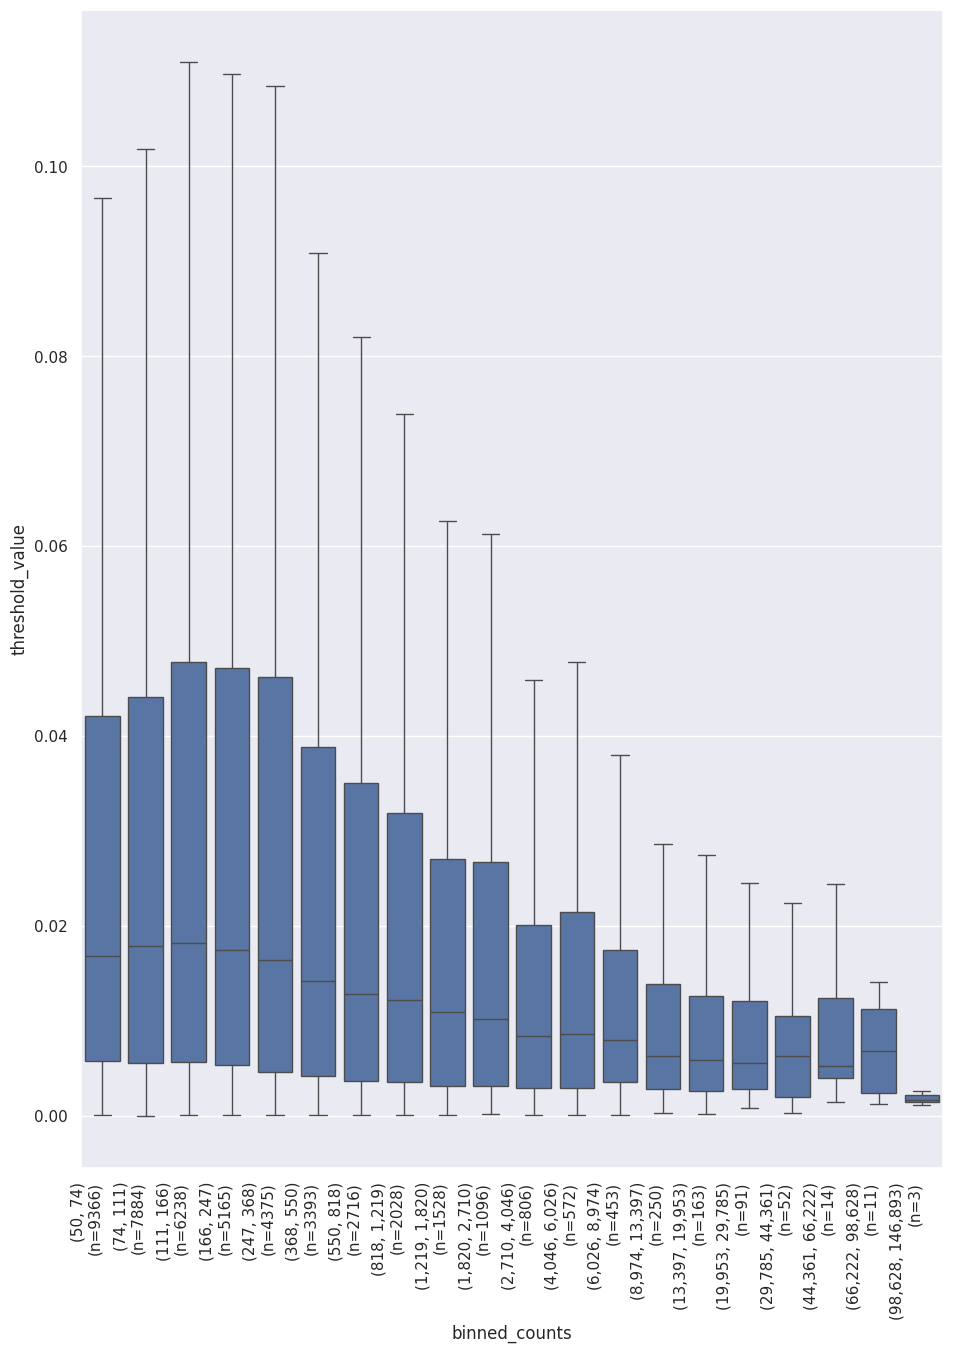

In [90]:
df = thresh_inat_2_21_lpt_r_5.copy()
df["log_train_counts"] = np.log10(df["train_counts"])
df["binned_counts"] = pd.cut(df["log_train_counts"], bins=20)

sns.boxplot(
    data=df,
    x="binned_counts",
    y="threshold_value",
    showfliers=False  # optionally hide extreme outliers for clarity
)
# plt.tick_params("x", rotation=90)

group_sizes = df.groupby("binned_counts").size()

# Convert log10 bin edges back to raw counts
bin_edges_log = df["binned_counts"].cat.categories
bin_edges_raw = [(round(10**b.left), round(10**b.right)) for b in bin_edges_log]

# Get sample sizes per bin
bin_counts = df.groupby("binned_counts").size()

# Create readable labels: "(100, 150) (n=52)"
bin_labels = [
    f"({left:,}, {right:,})\n(n={count})"
    for (left, right), count in zip(bin_edges_raw, bin_counts)
]

plt.xticks(
    ticks=np.arange(len(bin_labels)),
    labels=bin_labels,
    rotation=90,
    ha="right"
)

plt.tight_layout(pad=2.0)

plt.show()

/tmp/ipykernel_112697/1427944200.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_counts = df.groupby("binned_counts").size()


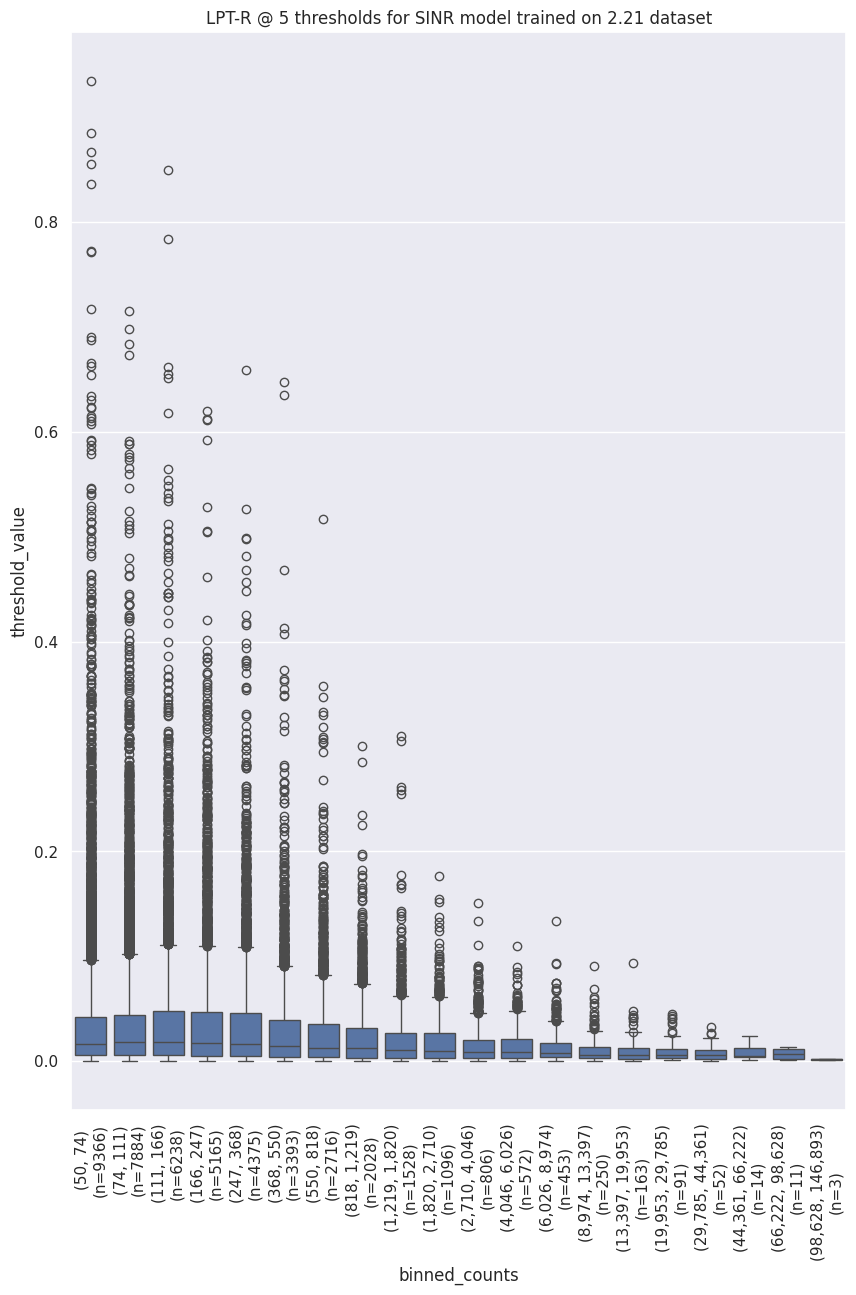

In [93]:

ax = sns.boxplot(
    data=df, x="binned_counts", y="threshold_value", showfliers=True,
)

# Build labels
bin_edges_log = df["binned_counts"].cat.categories
bin_edges_raw = [(round(10**b.left), round(10**b.right)) for b in bin_edges_log]
bin_counts = df.groupby("binned_counts").size()

labels = [
    f"({left:,}, {right:,})\n(n={count})"
    for (left, right), count in zip(bin_edges_raw, bin_counts)
]

# Apply labels using correct tick positions
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90, ha="center")

plt.title("LPT-R @ 5 thresholds for SINR model trained on 2.21 dataset")

plt.savefig("lpt_r_thresh_vs_train_counts_2_21.png")